# Plot-level digital canopy height (DCH) from UAV point clouds — reproduction of Fania et al. 2026

**Paper:** Fania, F. et al. (2026) 'Temporal GWAS and QTL mapping of UAV-derived digital canopy height reveals stage-specific genetic effects in bread wheat.', *Plant Phenomics* 8(4):100279. DOI: [10.1016/j.plaphe.2026.100279](https://doi.org/10.1016/j.plaphe.2026.100279) — open access (CC BY 4.0), PMCID [PMC13582003](https://pmc.ncbi.nlm.nih.gov/articles/PMC13582003/).

**Author code:** `devitagroup/Temporal-association-studies-on-digital-canopy-height` @ commit `337ec18fafdf` (reproducible_pipeline_dch.R, SHA-256 verified at runtime).
**Example data:** Zenodo record [21532537](https://zenodo.org/records/21532537) (CC-BY-4.0; De Vita & Fania), ~4.78 GB (two LAS point clouds + buffered-plot shapefile).

**Scope (partial demonstration):** this notebook reproduces the paper's core point-cloud processing subsection (Methods 2.3–2.4): density homogenization (1,500 pts/m² target, 50 m grid), DTM from a time-zero bare-soil cloud (0.05 m), height normalization (0–3 m), statistical outlier removal (SOR k=10, m=0.9), Gaussian smoothing (0.5 m, σ=1), and plot-level DCH40–DCH99 percentile extraction — the paper's digital canopy height trait pipeline. **It does not** cover temporal P-spline modelling, GWAS, QTL mapping, or candidate-gene analysis: per the paper's Data availability statement, phenotype/genotype tables are available only on reasonable request, and the authors state the example does not reproduce manuscript numbers.

**実行内容（日本語）:** 論文の中心であるUAV点群処理（密度均質化→DTM→正規化→ノイズ除去→平滑化→プロット別DCHパーセンタイル抽出）を、著者公開のRスクリプトとZenodoの例題点群でそのまま再現します。GWAS・QTL解析等は公開データがないため対象外です。

**Execution status / 実行状態:** fully executed on a fresh Google Colab **CPU** runtime (see validation record in the final section). The author R pipeline is executed via `Rscript` from Python launcher cells — Python is only the launcher, all science is the authors' R code.

**Adaptation notice / 改変の明示:** The author R script is run as-is except for **one display-only line** (the rgl 3D `plot()` call, which cannot open a window on a headless Colab VM) — it is replaced by a saved 2D canopy-height map of the same processed cloud, shown as a diff at runtime. No scientific operation is modified. The authors did not provide this Colab launcher; the executed example and listed checks were validated here, but untested behavior is not guaranteed.

## Runtime selection / ランタイム選択

**Use a standard CPU runtime (Runtime → Change runtime type → CPU).** The author pipeline is pure-CPU `lidR` processing; there is no GPU code path in the paper's implementation, so a GPU adds nothing. **CPU ランタイムを選択してください**（GPUは不要です）。

**Expected cost / 所要時間とダウンロード量** (measured on a standard CPU Colab runtime, Ubuntu 24.04 / R 4.6.1, 2 vCPU, ~12.7 GB RAM, on 2026-10-13; free-tier times vary):
- Zenodo download: **~4.78 GB**, about **23 min** at the observed ~3.5 MB/s.
- R packages: about **1 min** (apt binaries; the probe verified lidR 4.3.3, sf 1.1.3, terra 1.9.50, viridis 0.6.5).
- Pipeline: the canopy cloud has 86,299,133 points (1.9 GB in memory, read in 13 s); decimation to the 1,500 pts/m² target took ~24 s; **measured total pipeline wall time ≈ 55 min** on 2 vCPUs (the full-extent DTM interpolation dominates). This is a long-running demo; saved outputs remain useful.
- **This notebook downloads ~4.78 GB — well above a typical 2 GB demo** — because the authors' example dataset is the smallest paper-linked input and both clouds are required by their pipeline. Disk need ≈ 10 GB (probe observed 206 GB free). Memory peak ≈ 4–5 GB (measured cloud sizes) — fits the standard ~12.7 GB CPU runtime.

**Run all** (Runtime → Run all) executes everything end to end. All data stays under `/content` on the Colab VM.

**Cell 1 — Environment report.**
Check CPU count, RAM, disk, R availability, and the Ubuntu release. Expected: a
standard Colab CPU runtime (~2 vCPU, ~12.7 GB RAM) with R preinstalled; these
values are used to interpret the measured runtimes below.

In [ ]:
import subprocess, os

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()

print("cpus:", os.cpu_count())
for line in open("/proc/meminfo"):
    if line.startswith(("MemTotal", "MemAvailable")):
        print(line.strip())
print("disk:", sh("df -h /content | tail -1"))
print("ubuntu:", sh("lsb_release -ds 2>/dev/null") or sh("grep PRETTY /etc/os-release"))
print("R:", sh("Rscript --version"))

cpus: 2
MemTotal:       13286944 kB
MemAvailable:   12370492 kB
disk: overlay         226G   21G  206G  10% /
ubuntu: Ubuntu 24.04.5 LTS
R: Rscript (R) version 4.6.1 (2026-06-24)


**Cell 2 — Install the R dependencies (apt binaries).**
The author script needs `lidR`, `sf`, `terra`, and `viridis` (README, "Software
requirements"). The probe observed these resolve from apt in seconds on the
current Colab image; the r2u bootstrap may exit nonzero harmlessly. Expected:
about a minute. The next cell verifies and falls back to CRAN source builds
only if anything is missing.

In [ ]:
import subprocess, time

t0 = time.time()
r = subprocess.run("curl -sL https://eddelbuettel.github.io/r2u/assets/install.sh | bash",
                   shell=True, executable="/bin/bash")
print(f"r2u setup rc={r.returncode} in {time.time()-t0:.0f}s")
t0 = time.time()
env = dict(os.environ, DEBIAN_FRONTEND="noninteractive")
r = subprocess.run(["apt-get", "install", "-y", "-qq",
                    "r-cran-lidr", "r-cran-sf", "r-cran-terra", "r-cran-viridis"], env=env)
print(f"apt install rc={r.returncode} in {time.time()-t0:.0f}s")

r2u setup rc=2 in 0s


apt install rc=0 in 19s


**Cell 3 — Verify the R packages (CRAN source fallback).**
Load all four packages from R and print their versions. If anything is missing,
install from CRAN source so the run can still proceed (slower path).

In [ ]:
import subprocess, time

chk = subprocess.run(["Rscript", "-e",
    'for (p in c("lidR","sf","terra","viridis")) '
    'cat(p, as.character(packageVersion(p)), "\n")'],
    capture_output=True, text=True)
print(chk.stdout, chk.stderr)
if chk.returncode != 0 or "lidR" not in chk.stdout:
    t0 = time.time()
    subprocess.run(["Rscript", "-e",
        'options(repos = c(CRAN = "https://cloud.r-project.org")); '
        'install.packages(c("rlas", "lidR", "sf", "terra", "viridis"))'])
    print(f"CRAN fallback finished in {time.time()-t0:.0f}s")
    assert subprocess.run(["Rscript", "-e", 'library(lidR)']).returncode == 0

lidR 4.3.3 
sf 1.1.3 
terra 1.9.50 
viridis 0.6.5 
 


**Cell 4 — Download the example dataset from Zenodo (metadata + small files).**
Query Zenodo record 21532537 at runtime, download the five shapefile components
into `/content/data/`, and verify each file's MD5 against the checksum recorded
in the record itself. The two large LAS clouds follow in the next cell.

In [ ]:
import json, os, subprocess, hashlib, time, urllib.request

os.makedirs("/content/data", exist_ok=True)
rec = json.load(urllib.request.urlopen("https://zenodo.org/api/records/21532537", timeout=60))
files = {f["key"]: f for f in rec["files"]}
print("record:", rec["doi"], "| license:", rec["metadata"]["license"]["id"])

def dl(key):
    f = files[key]
    dest = f"/content/data/{key}"
    t0 = time.time()
    subprocess.run(["curl", "-sSL", "--retry", "5", "--retry-delay", "5",
                    "-o", dest, f["links"]["self"]], check=True)
    md5 = hashlib.md5(open(dest, "rb").read()).hexdigest()
    ok = md5 == f["checksum"].split(":", 1)[1]
    print(f"{key}: {os.path.getsize(dest):,} B in {time.time()-t0:.1f}s md5_ok={ok}")
    assert ok, f"MD5 mismatch for {key}"

for k in sorted(files):
    if k.endswith((".shp", ".shx", ".dbf", ".prj", ".cpg")):
        dl(k)

record: 10.5281/zenodo.21532537 | license: cc-by-4.0


all_trial_complete_buffer.cpg: 5 B in 0.5s md5_ok=True


all_trial_complete_buffer.dbf: 45,824 B in 0.9s md5_ok=True


all_trial_complete_buffer.prj: 401 B in 0.5s md5_ok=True


all_trial_complete_buffer.shp: 53,140 B in 0.9s md5_ok=True


all_trial_complete_buffer.shx: 3,220 B in 0.6s md5_ok=True


**Cell 5 — Download the two LAS point clouds (heavy step).**
Fetch the bare-soil (1.85 GB) and canopy (2.93 GB) clouds with curl
resume/retry and verify MD5 against the Zenodo record. Observed at
~3.5 MB/s this takes about **23 min**; the files are kept under
`/content/data/` on the Colab VM.

In [ ]:
import time, subprocess, os

for k in ("timepoint_0_bare_soil.las", "timepoint_X_canopy.las"):
    dest = f"/content/data/{k}"
    t0 = time.time()
    subprocess.run(["curl", "-sSL", "--retry", "5", "--retry-delay", "5", "-C", "-",
                    "-o", dest, files[k]["links"]["self"]], check=True)
    print(f"{k}: {os.path.getsize(dest):,} B in {time.time()-t0:.0f}s")
    md5 = subprocess.run(["md5sum", dest], capture_output=True, text=True).stdout.split()[0]
    ok = md5 == files[k]["checksum"].split(":", 1)[1]
    print("  md5_ok =", ok)
    assert ok, f"MD5 mismatch for {k}"

timepoint_0_bare_soil.las: 1,846,460,297 B in 600s


  md5_ok = True


timepoint_X_canopy.las: 2,934,171,603 B in 781s


  md5_ok = True


**Cell 6 — Retrieve and patch the author pipeline (one display-only change).**
Download `reproducible_pipeline_dch.R` from the pinned commit `337ec18fafdf`,
verify its SHA-256 against the reviewed source, then create a headless copy in
which the single rgl 3D display line (line 245) is replaced by a saved 2D
canopy-height map of the same processed cloud. The unified diff is printed so
the change is fully auditable; every scientific operation is untouched.

In [ ]:
import hashlib, urllib.request, difflib

src = urllib.request.urlopen("https://raw.githubusercontent.com/devitagroup/Temporal-association-studies-on-digital-canopy-height/337ec18fafdf9ffe4819ae5c63188352b2a6f823/reproducible_pipeline_dch.R", timeout=60).read()
sha = hashlib.sha256(src).hexdigest()
print("sha256:", sha)
assert sha == "055fa677931c06b8815d2c9df68de54342b97cffa86008ee9a2007da22a3a328", "pinned author script hash mismatch"

orig = src.decode()
OLD = 'plot(las_smoothed, color = "Z", pal = mako, breaks = "quantile", legend = T)'
NEW = """# [HEADLESS ADAPTATION - replaces the author's rgl 3D display line (L245).
#  Same processed cloud, rendered to a PNG instead of an rgl window.]
set.seed(42)
png(file.path(output_dir, "canopy_height_map.png"), width = 1200, height = 900, res = 120)
n_sub <- min(400000, npoints(las_smoothed))
idx <- sample.int(npoints(las_smoothed), n_sub)
zbrk <- cut(las_smoothed@data$Z[idx], breaks = 50)
plot(las_smoothed@data$X[idx], las_smoothed@data$Y[idx],
     col = viridis::viridis(50)[zbrk], pch = ".", asp = 1,
     xlab = "X (m)", ylab = "Y (m)",
     main = "Smoothed canopy cloud (subsample), colored by height Z (m)")
dev.off()"""
assert orig.count(OLD) == 1, "expected exactly one rgl display line"
patched = orig.replace(OLD, NEW)
open("/content/reproducible_pipeline_dch_patched.R", "w").write(patched)

diff = difflib.unified_diff(orig.splitlines(True), patched.splitlines(True),
                            "author@337ec18fafdf", "headless-patched", n=1)
print("".join(diff))

sha256: 055fa677931c06b8815d2c9df68de54342b97cffa86008ee9a2007da22a3a328
--- author@337ec18fafdf
+++ headless-patched
@@ -244,3 +244,14 @@
 #3D plotting (with external window)
-plot(las_smoothed, color = "Z", pal = mako, breaks = "quantile", legend = T)
+# [HEADLESS ADAPTATION - replaces the author's rgl 3D display line (L245).
+#  Same processed cloud, rendered to a PNG instead of an rgl window.]
+set.seed(42)
+png(file.path(output_dir, "canopy_height_map.png"), width = 1200, height = 900, res = 120)
+n_sub <- min(400000, npoints(las_smoothed))
+idx <- sample.int(npoints(las_smoothed), n_sub)
+zbrk <- cut(las_smoothed@data$Z[idx], breaks = 50)
+plot(las_smoothed@data$X[idx], las_smoothed@data$Y[idx],
+     col = viridis::viridis(50)[zbrk], pch = ".", asp = 1,
+     xlab = "X (m)", ylab = "Y (m)",
+     main = "Smoothed canopy cloud (subsample), colored by height Z (m)")
+dev.off()
 



**Cell 7 — Input preview: buffered plot polygons and LAS headers.**
Before the core processing, inspect the actual inputs: plot the buffered plot
polygons from the shapefile and print each LAS header (point count, extents)
via lidR's `readLASheader()`. Expected: 390 buffered plots with an `id`
identifier field, and two large point clouds covering the same projected
extent.

[1] "plots: 390 fields: id,left,top,right,bottom,geometry"
[1] "CRS: WGS 84 / UTM zone 33N"
[1] "bare soil: 54307624 pts, extent X 541406-541628.9"
[1] "canopy: 86299133 pts, extent X 541399.4-541633.9"
null device 
          1 



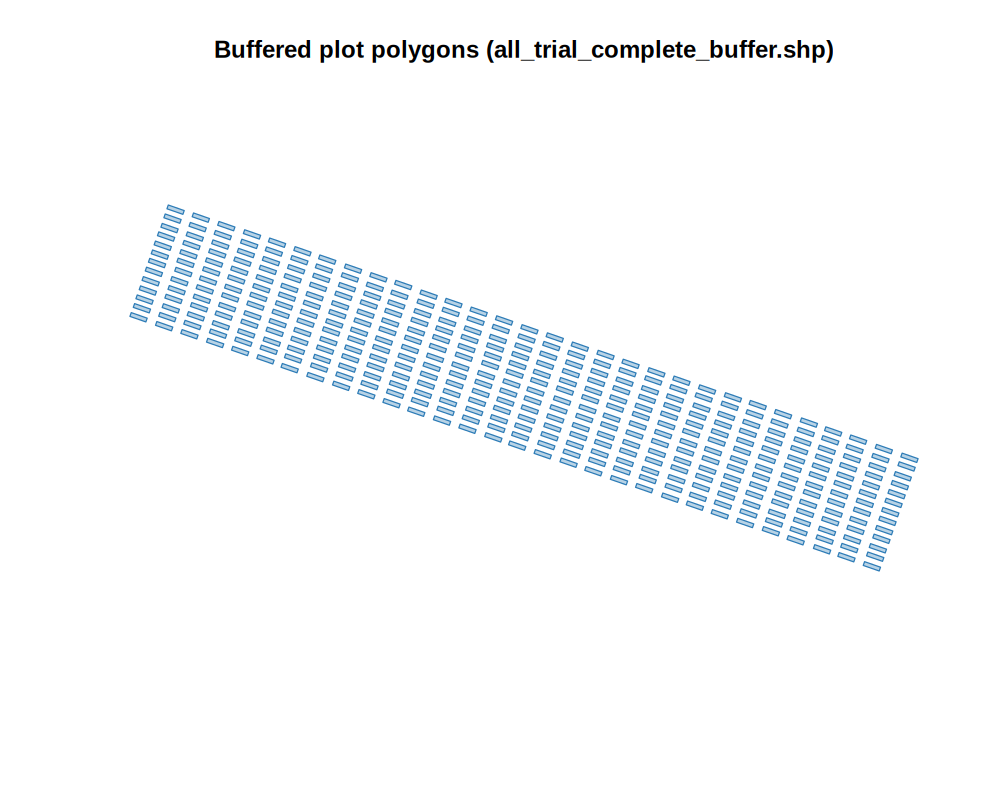

In [ ]:
open("/content/preview.R", "w").write("\n".join([
    "suppressPackageStartupMessages({library(lidR); library(sf)})",
    'plots <- st_read("data/all_trial_complete_buffer.shp", quiet = TRUE)',
    'print(paste0("plots: ", nrow(plots), " fields: ", paste(names(plots), collapse = ",")))',
    'print(paste0("CRS: ", st_crs(plots)$input))',
    'h0 <- readLASheader("data/timepoint_0_bare_soil.las")',
    'hx <- readLASheader("data/timepoint_X_canopy.las")',
    'print(paste0("bare soil: ", h0@PHB$`Number of point records`, " pts, extent X ",',
    '             round(h0@PHB$`Min X`, 1), "-", round(h0@PHB$`Max X`, 1)))',
    'print(paste0("canopy: ", hx@PHB$`Number of point records`, " pts, extent X ",',
    '             round(hx@PHB$`Min X`, 1), "-", round(hx@PHB$`Max X`, 1)))',
    'png("/content/input_preview_plots.png", width = 1000, height = 800, res = 120)',
    'plot(st_geometry(plots), col = "#2c7bb655", border = "#2c7bb6",',
    '     main = "Buffered plot polygons (all_trial_complete_buffer.shp)")',
    'dev.off()',
]))
import subprocess
with open("/content/preview.log", "w") as logf:
    r = subprocess.run(["Rscript", "/content/preview.R"],
                       stdout=logf, stderr=subprocess.STDOUT)
print(open("/content/preview.log").read())
assert r.returncode == 0, "input preview failed - see preview.log above"
from IPython.display import Image, display
display(Image(filename="/content/input_preview_plots.png"))

**Cell 8 — Run the author pipeline end to end.**
Execute the SHA-256-verified, headless-patched author script under `Rscript`
with all output streamed. This performs, in the authors' own code: density
summary, homogenization (1,500 pts/m², 50 m grid), bare-soil DTM (0.05 m,
p2r + knnidw fill), normalization (0–3 m), SOR denoising, Gaussian smoothing
(0.5 m, σ=1), and plot-level DCH40–DCH99 extraction, writing
`output/plot_level_DCH_percentiles.csv`, `output/timepoint_0_DTM.tif`, and
`output/canopy_height_map.png`. This is the longest cell.

In [ ]:
open("/content/run_pipeline.R", "w").write("\n".join([
    "## Driver: run the authors' pinned pipeline, then notebook-added display/export steps.",
    'setwd("/content")',
    'source("/content/reproducible_pipeline_dch_patched.R")',
    "## ---- notebook-added (not part of the author script): export density summary ----",
    'write.csv(density_summary, file.path(output_dir, "point_cloud_density_summary.csv"),',
    '          row.names = FALSE)',
    "## ---- notebook-added: DCH90 choropleth map over the buffered plot polygons ----",
    'm <- merge(plots, dch_table, by.x = plot_id_field, by.y = "plot_id")',
    'png(file.path(output_dir, "dch90_map.png"), width = 1200, height = 900, res = 120)',
    'plot(m["DCH90"], main = "DCH90 (m) per buffered plot")',
    'dev.off()',
    "## ---- notebook-added: DCH90 distribution ----",
    'png(file.path(output_dir, "dch90_histogram.png"), width = 1200, height = 600, res = 120)',
    'hist(dch_table$DCH90, col = "#44015488", xlab = "DCH90 (m)",',
    '     main = "Distribution of plot-level DCH90 (example data)")',
    'dev.off()',
]))
import subprocess, time
t0 = time.time()
with open("/content/pipeline.log", "w") as logf:
    r = subprocess.run(["Rscript", "/content/run_pipeline.R"],
                       stdout=logf, stderr=subprocess.STDOUT, timeout=10800)
log = open("/content/pipeline.log").read()
print(log[-4000:])
print(f"pipeline rc={r.returncode} wall={(time.time()-t0)/60:.1f} min")
assert r.returncode == 0, "pipeline failed - see pipeline.log above"

 59% (1 threads)
Point cloud smoothing: [==============================--------------------] 60% (1 threads)
Point cloud smoothing: [==============================--------------------] 61% (1 threads)
Point cloud smoothing: [===============================-------------------] 62% (1 threads)
Point cloud smoothing: [===============================-------------------] 63% (1 threads)
Point cloud smoothing: [================================------------------] 64% (1 threads)
Point cloud smoothing: [================================------------------] 65% (1 threads)
Point cloud smoothing: [=================================-----------------] 66% (1 threads)
Point cloud smoothing: [=================================-----------------] 67% (1 threads)
Point cloud smoothing: [==================================----------------] 68% (1 threads)
Point cloud smoothing: [==================================----------------] 69% (1 threads)
Point cloud smoothing: [===================================----

**Cell 9 — Inspect the extracted DCH percentile table.**
Load `plot_level_DCH_percentiles.csv` (one row per plot: retained point count
and DCH40–DCH99 in metres) and `point_cloud_density_summary.csv` (points,
area, and density before/after homogenization) as DataFrames.

In [ ]:
import pandas as pd

dch = pd.read_csv("/content/output/plot_level_DCH_percentiles.csv")
print("DCH table:", dch.shape)
display(dch.head(10))
dens = pd.read_csv("/content/output/point_cloud_density_summary.csv")
print("Density summary:")
display(dens)

DCH table: (390, 9)


,plot_id,n_points,DCH40,DCH50,DCH60,DCH70,DCH80,DCH90,DCH99
0,841,3993,0.363,0.374,0.3840,0.394,0.4030,0.413,0.43400
1,842,4047,0.505,0.513,0.5210,0.528,0.5360,0.546,0.55500
2,843,3955,0.410,0.418,0.4240,0.430,0.4370,0.445,0.45900
3,845,4074,0.409,0.412,0.4150,0.419,0.4260,0.435,0.45100
4,846,4225,0.521,0.527,0.5350,0.543,0.5540,0.568,0.58076
5,847,4343,0.422,0.429,0.4380,0.445,0.4550,0.468,0.48600
6,848,4638,0.347,0.353,0.3600,0.367,0.3760,0.384,0.39600
7,849,5400,0.456,0.461,0.4660,0.469,0.4732,0.482,0.48900
8,850,5128,0.510,0.518,0.5262,0.536,0.5440,0.553,0.56800
9,851,5105,0.580,0.590,0.5970,0.604,0.6100,0.621,0.63500


Density summary:


,stage,points,area_m2,density_points_m2,target_density_points_m2,homogenization_grid_m
0,before_decimation,86299133,40752,2117.6662,1500,50
1,after_decimation,56888113,40752,1395.9588,1500,50


**Cell 10 — Display the saved result figures.**
Show the three PNGs produced on the VM: the smoothed canopy height map from
the patched display line, the notebook-added DCH90 choropleth, and the DCH90
distribution. These are outputs of this run, not figures from the paper.

output/canopy_height_map.png


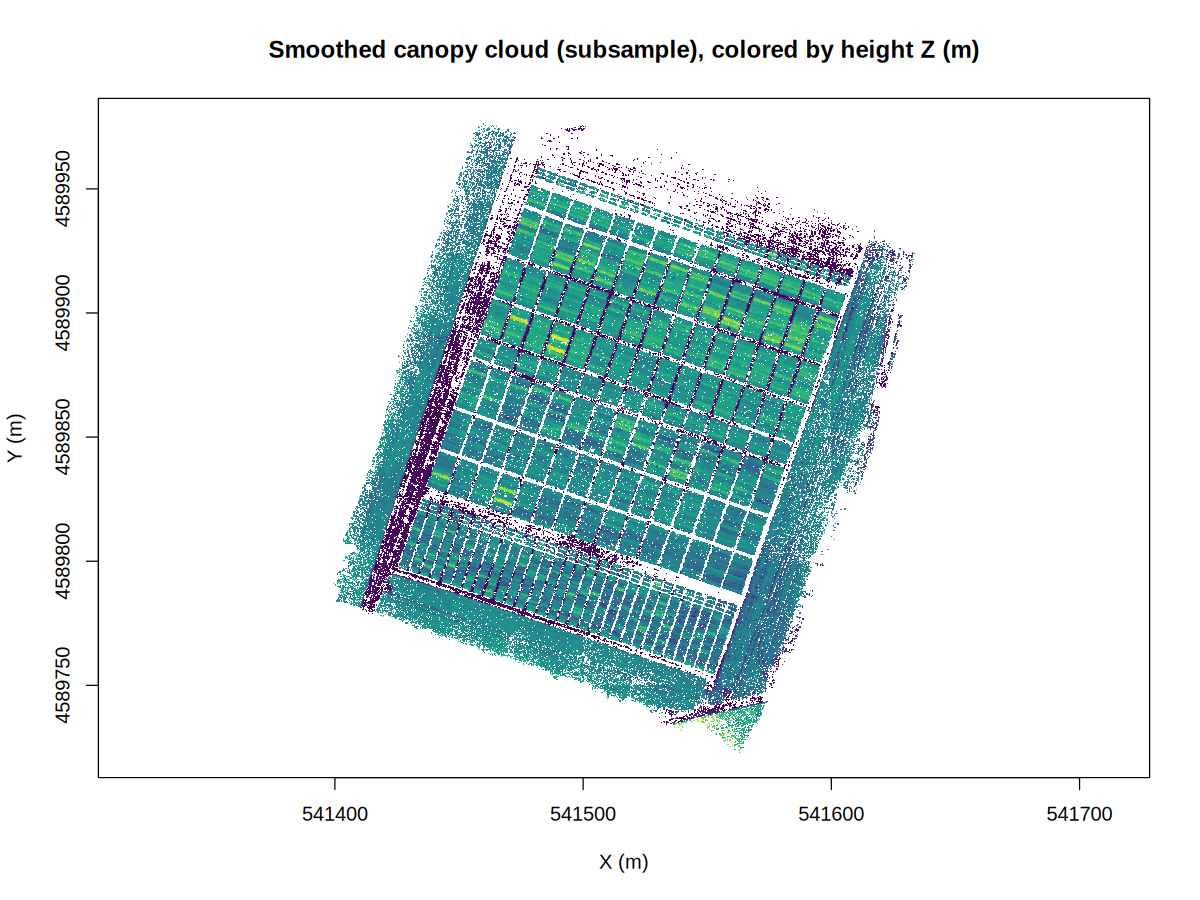

output/dch90_map.png


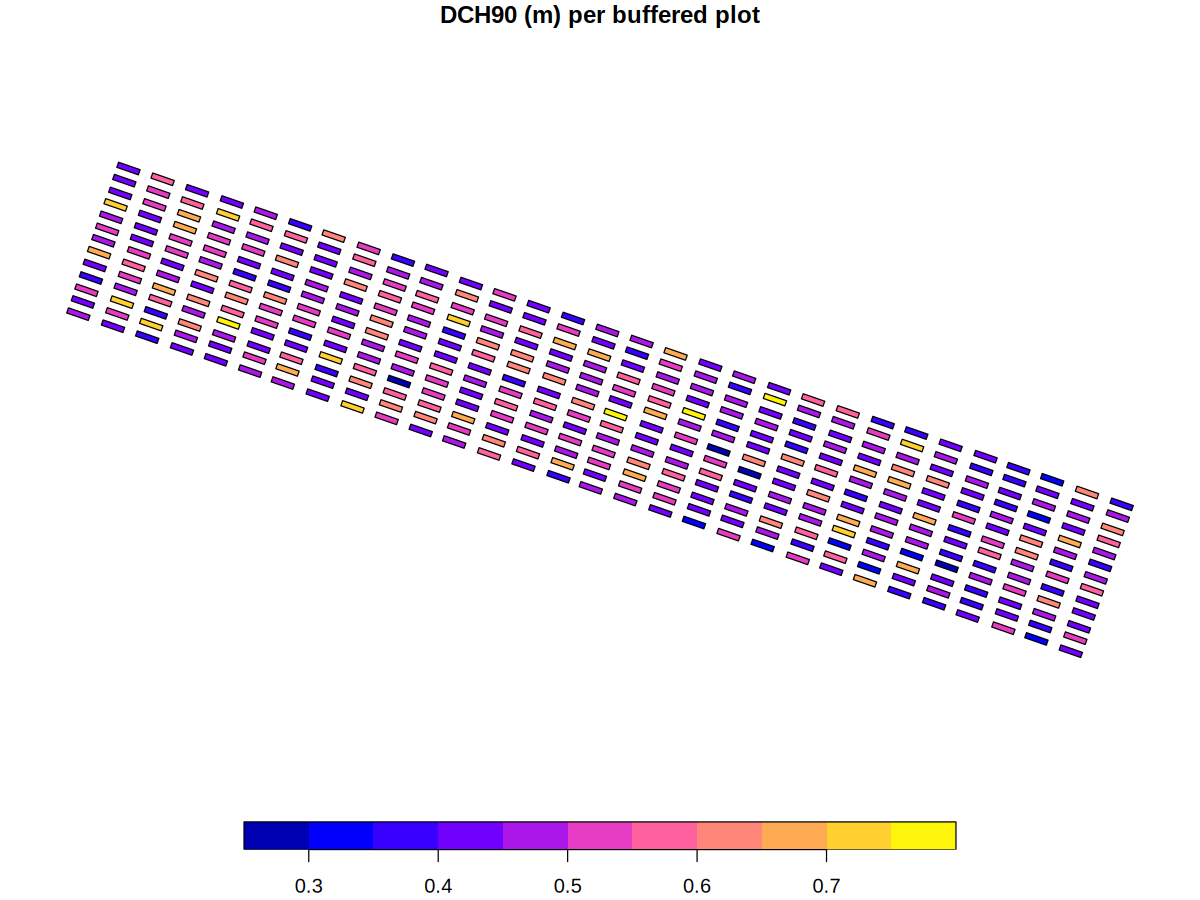

output/dch90_histogram.png


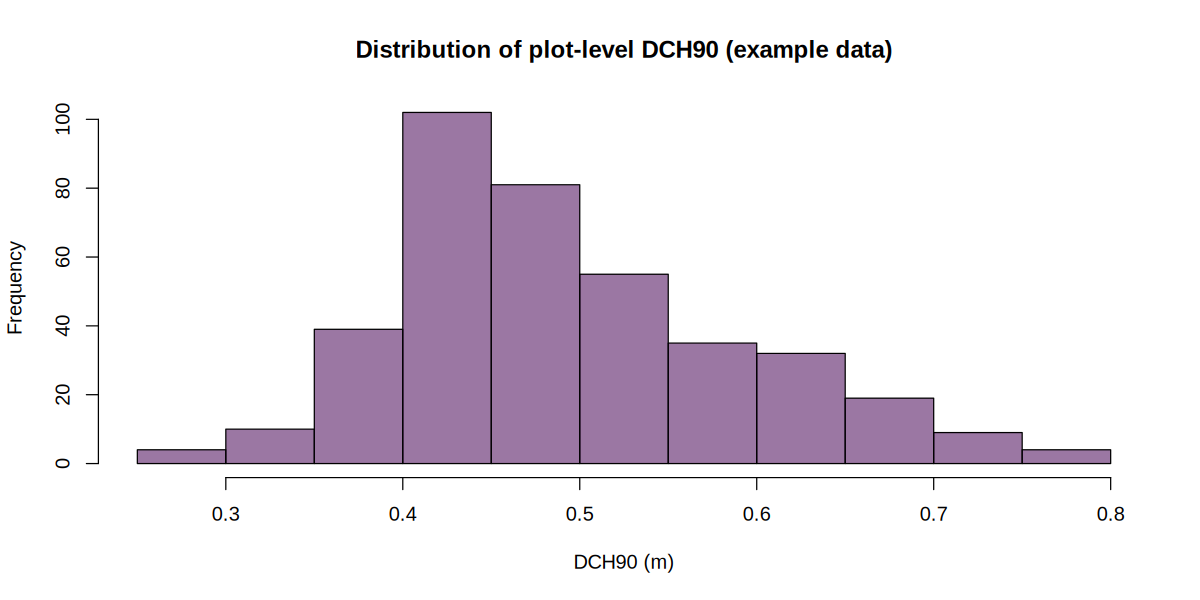

In [ ]:
from IPython.display import Image, display

for p in ("output/canopy_height_map.png", "output/dch90_map.png",
          "output/dch90_histogram.png"):
    print(p)
    display(Image(filename=f"/content/{p}"))

**Cell 11 — Session record.**
Print the R `sessionInfo()` the author script saved, documenting the exact R
and package versions used for this reproduction.

In [ ]:
print(open("/content/output/sessionInfo.txt").read())

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] viridis_0.6.5     viridisLite_0.4.3 terra_1.9-50      sf_1.1-3         
[5] lidR_4.3.3       

loaded via a namespace (and not attached):
 [1] gtable_0.3.6        dplyr_1.2.1 

## Interpretation and limitations / 解釈と限界

**What was reproduced:** the authors' own R pipeline (`reproducible_pipeline_dch.R` @
`337ec18fafdf`, SHA-256-verified) executed end to end on their Zenodo example
(record 21532537, CC-BY-4.0): density homogenization, DTM from bare soil,
normalization, SOR denoising, Gaussian smoothing, and plot-level DCH40–DCH99 —
the paper's Section 2.3–2.4 point-cloud processing, on the example dataset.

**What was NOT reproduced / 未実行の部分:** temporal P-spline modelling, GWAS, QTL
mapping, and candidate-gene analysis. The paper's Data availability statement
restricts phenotype/genotype tables to reasonable request, and the authors state
the example does not reproduce manuscript numbers (README, "Interpretation of the
example"). The DCH values here are from a de-identified example, not the published
study results. **この例題のDCH値は論文の発表結果を再現するものではありません。**

**Adaptations:** exactly one display-only line replaced (headless render, diff shown
in Cell 6); density-summary CSV export and the two DCH figures are notebook-added
visualizations, clearly labeled. Python cells only launch `Rscript`.

**License/attribution:** example data CC-BY-4.0 (De Vita & Fania, Zenodo 21532537).
The author repository has no LICENSE file; the script is executed (not
redistributed) and cited with its pinned commit. Questions: fabio.fania@crea.gov.it.

**References:** Fania F, Spadanuda P, Puglisi D, Angione G, Colella I, Pecorella I,
Esposito S, De Vita P. Temporal GWAS and QTL mapping of UAV-derived digital canopy
height reveals stage-specific genetic effects in bread wheat. Plant Phenomics.
2026;8(4):100279. doi:10.1016/j.plaphe.2026.100279 (PMCID PMC13582003);
devitagroup/Temporal-association-studies-on-digital-canopy-height @ 337ec18fafdf;
Zenodo 21532537.